# Online Retail Customer Purchase Prediction Using Machine Learning

## 1. Problem Definition

The objective of this project is to develop a machine learning classification model that predicts whether an existing customer is likely to make a purchase in a future period based on their historical purchasing behaviour.

The project uses the Online Retail transaction dataset, which contains information about invoices, products, quantities, transaction dates, unit prices, customers and countries.

The project follows an end-to-end machine learning workflow including data understanding, data preprocessing, exploratory data analysis, feature engineering, model development, model validation, hyperparameter tuning, model evaluation, model comparison and prediction on unseen data.

## 2. Importing Required Libraries

### What we do
We import the Python libraries required for data manipulation, visualization, preprocessing, machine learning model development and model evaluation.

### Why we do it
Different stages of the project require different tools. Pandas and NumPy are used for data processing, Matplotlib and Seaborn for visualization, and Scikit-learn for machine learning.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully.")

All required libraries imported successfully.


## 3. Dataset Loading

The Online Retail dataset is loaded using Pandas. This dataset contains transaction-level information about customer purchases, including invoice number, product description, quantity, invoice date, unit price, customer ID, and country.

The purpose of this step is to load the dataset and verify that the data has been read correctly before performing preprocessing and exploratory data analysis.

In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl scipy joblib ipykernel

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Load the Online Retail dataset

df = pd.read_csv(
    "data/OnlineRetail.csv",
    encoding="ISO-8859-1"
)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


## 4. Dataset Understanding

The dataset contains 541,909 transaction records and 8 variables.
In this section, we examine the structure, data types, and sample records
to understand the dataset before performing preprocessing.

In [ ]:
# Understand the dataset structure

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 5. Missing Value Analysis

Missing values may affect the quality of analysis and machine learning.
Therefore, we identify the number of missing values present in each column.

In [ ]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values)

Missing Values in Each Column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 6. Handling Missing Values

The dataset contains missing values in the Description and CustomerID columns.
The CustomerID column is important for customer-level analysis and prediction,
so records without a CustomerID cannot be reliably associated with a customer.
The Description column contains only a small number of missing values.

Therefore, rows with missing CustomerID or Description values are removed.
This avoids creating artificial values and ensures reliable customer-level
feature engineering.

In [ ]:
# Check the number of rows before removing missing values

print("Rows before removing missing values:", len(df))

# Remove rows with missing CustomerID or Description
df = df.dropna(subset=["CustomerID", "Description"])

print("Rows after removing missing values:", len(df))

# Verify that missing values are handled
print("\nRemaining missing values:")
print(df.isnull().sum())

Rows before removing missing values: 541909
Rows after removing missing values: 406829

Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


## 7. Duplicate Record Analysis and Removal

Duplicate transaction records can affect the reliability of analysis and
machine learning models. Therefore, duplicate rows are identified and
removed from the cleaned dataset.

In [ ]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 5225


### Removing Duplicate Records

A total of 5,225 duplicate records were identified in the dataset.
These duplicate rows are removed to prevent repeated transactions from
affecting the analysis and machine learning models.

In [ ]:
# Remove duplicate records

before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Rows before removing duplicates:", before)
print("Duplicate records removed:", before - after)
print("Rows after removing duplicates:", after)

Rows before removing duplicates: 406829
Duplicate records removed: 5225
Rows after removing duplicates: 401604


In [ ]:
# Verify that duplicates have been removed

print("Remaining duplicate records:", df.duplicated().sum())

Remaining duplicate records: 0


## 8. Transaction Data Quality Check

The Online Retail dataset may contain cancelled transactions, returned
products, and invalid transaction values. Negative quantities can represent
returns or cancellations, while zero or negative unit prices are not useful
for purchase-value analysis.

Therefore, these transaction characteristics are examined before deciding
how the data should be prepared for machine learning.

In [ ]:
# Check negative quantities
negative_quantity = (df["Quantity"] < 0).sum()

# Check zero or negative unit prices
invalid_price = (df["UnitPrice"] <= 0).sum()

# Check cancelled invoices
cancelled_invoices = df["InvoiceNo"].astype(str).str.startswith("C").sum()

print("Negative Quantity records:", negative_quantity)
print("Zero/Negative UnitPrice records:", invalid_price)
print("Cancelled invoices:", cancelled_invoices)

Negative Quantity records: 8872
Zero/Negative UnitPrice records: 40
Cancelled invoices: 8872


## 8. Transaction Data Cleaning

The dataset contains 8,872 transactions with negative quantities, which
correspond to cancelled or returned transactions. Since the objective is to
predict future customer purchases, these records are excluded from the
purchase-history data.

There are also 40 transactions with zero or negative UnitPrice. These records
are excluded because they do not represent valid positive-value purchases.

After removing these records, the remaining transactions represent valid
positive-value purchases suitable for further analysis and feature engineering.

In [ ]:
# Remove cancelled/returned transactions
df = df[df["Quantity"] > 0]

# Remove invalid prices
df = df[df["UnitPrice"] > 0]

print("Rows after transaction cleaning:", len(df))
print("Negative Quantity records remaining:", (df["Quantity"] < 0).sum())
print("Invalid UnitPrice records remaining:", (df["UnitPrice"] <= 0).sum())

Rows after transaction cleaning: 392692
Negative Quantity records remaining: 0
Invalid UnitPrice records remaining: 0


## 9. Date Conversion and Purchase Value

The InvoiceDate column is converted into datetime format so that useful
time-based features can be extracted.

A TotalAmount feature is also created by multiplying Quantity by UnitPrice.
This represents the total monetary value of each transaction and will be
useful for customer-level analysis and feature engineering.

In [ ]:
# Convert InvoiceDate to datetime

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Calculate total transaction amount

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

# Display the updated dataset

display(df.head())

print("InvoiceDate data type:", df["InvoiceDate"].dtype)
print("TotalAmount feature created successfully.")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


InvoiceDate data type: datetime64[us]
TotalAmount feature created successfully.


## 10. Descriptive Statistics After Cleaning

Descriptive statistics are examined after data cleaning to understand the
distribution and range of the cleaned transaction data.

In [ ]:
display(df[["Quantity", "UnitPrice", "TotalAmount"]].describe())

,Quantity,UnitPrice,TotalAmount
count,392692.000000,392692.000000,392692.000000
mean,13.119702,3.125914,22.631500
std,180.492832,22.241836,311.099224
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.450000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


## 11. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution and
patterns in the cleaned transaction data. The analysis focuses on transaction
quantity, unit price, purchase amount, customer activity, and country-level
patterns.

### 11.1 Distribution of Quantity

The distribution of transaction quantity is visualized to understand the
typical purchase quantity and identify extreme observations.

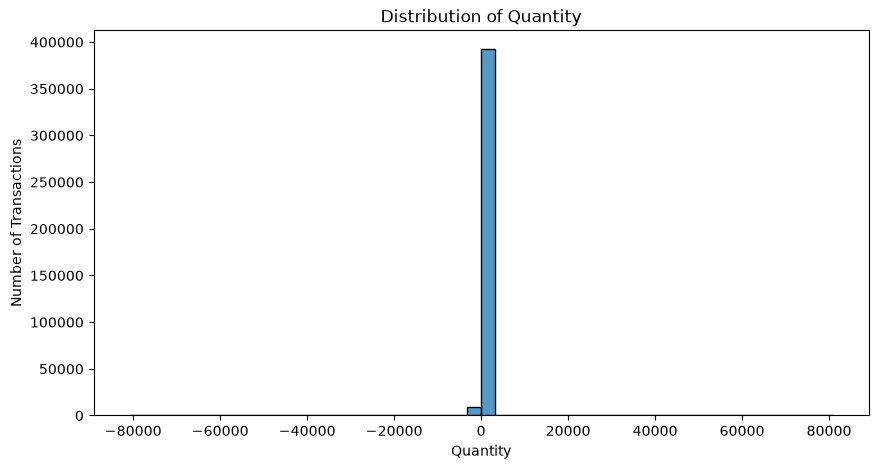

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Quantity"], bins=50)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")
plt.show()

### 11.2 Distribution of Total Transaction Amount

The distribution of TotalAmount is examined to understand customer
transaction values and identify potential extreme observations.

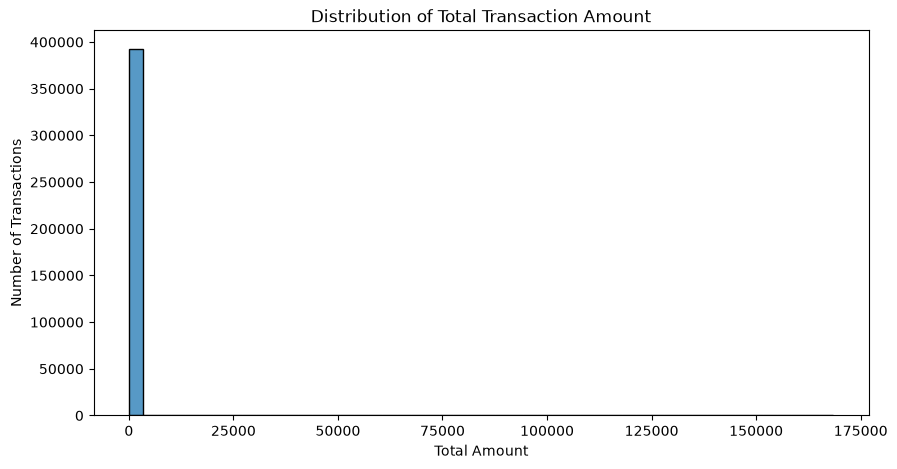

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["TotalAmount"], bins=50)

plt.title("Distribution of Total Transaction Amount")
plt.xlabel("Total Amount")
plt.ylabel("Number of Transactions")
plt.show()

### 11.3 Boxplot Analysis of Numerical Features

Boxplots are used to identify the spread of numerical variables and detect potential outliers.

The boxplots are created for Quantity, UnitPrice, and TotalAmount because these variables contain numerical transaction information.

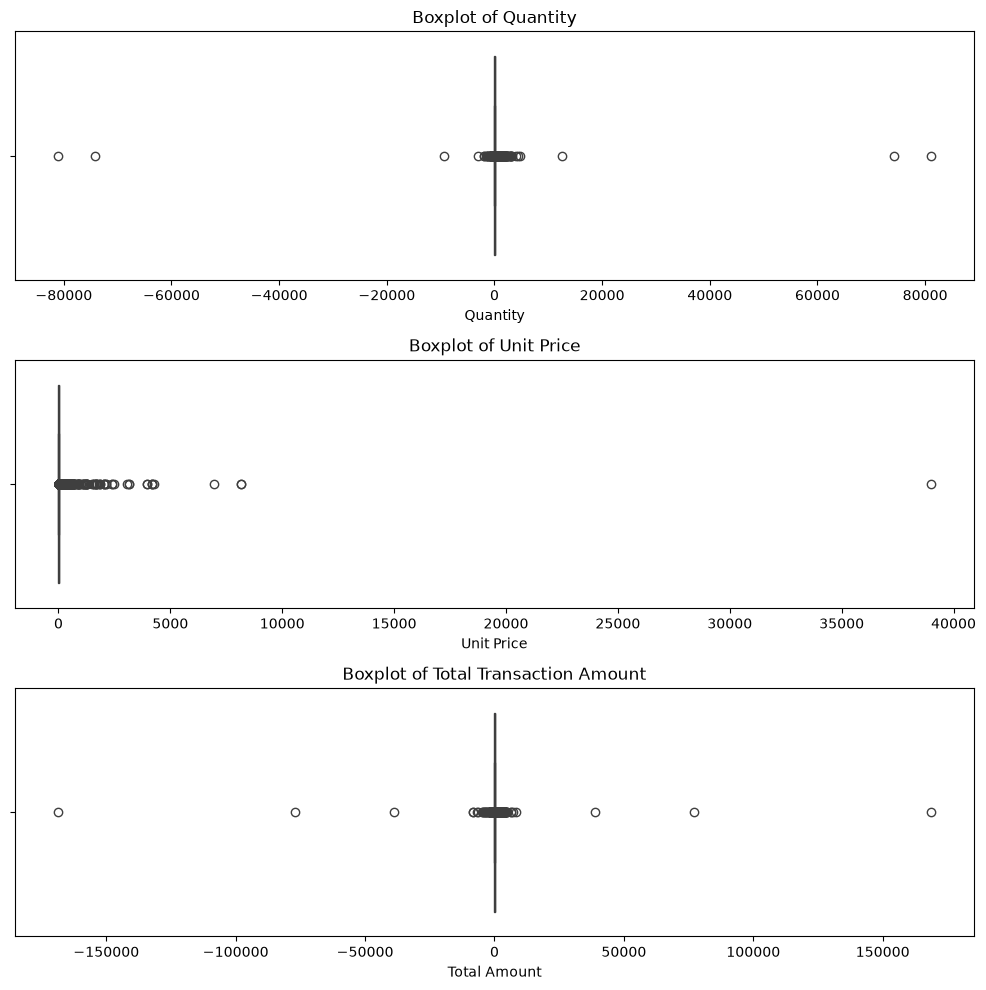

In [ ]:
# Boxplot analysis of numerical features

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# Boxplot for Quantity
sns.boxplot(x=df["Quantity"], ax=axes[0])
axes[0].set_title("Boxplot of Quantity")
axes[0].set_xlabel("Quantity")

# Boxplot for UnitPrice
sns.boxplot(x=df["UnitPrice"], ax=axes[1])
axes[1].set_title("Boxplot of Unit Price")
axes[1].set_xlabel("Unit Price")

# Boxplot for TotalAmount
sns.boxplot(x=df["TotalAmount"], ax=axes[2])
axes[2].set_title("Boxplot of Total Transaction Amount")
axes[2].set_xlabel("Total Amount")

plt.tight_layout()
plt.show()

### 11.3 Transactions by Country

The number of transactions from different countries is analyzed to identify
the major geographical markets represented in the dataset.

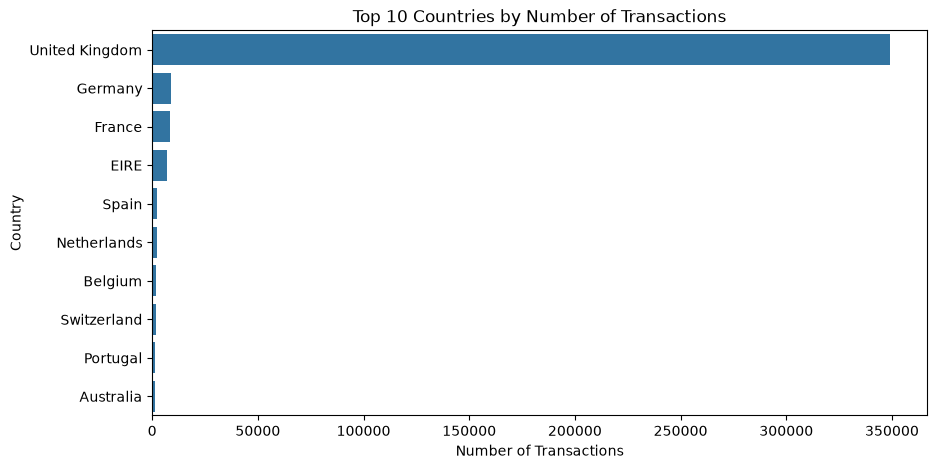

In [ ]:
country_counts = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")
plt.show()

### 11.4 Monthly Sales Trend

Monthly sales are analyzed to identify changes and trends in transaction
revenue over time.

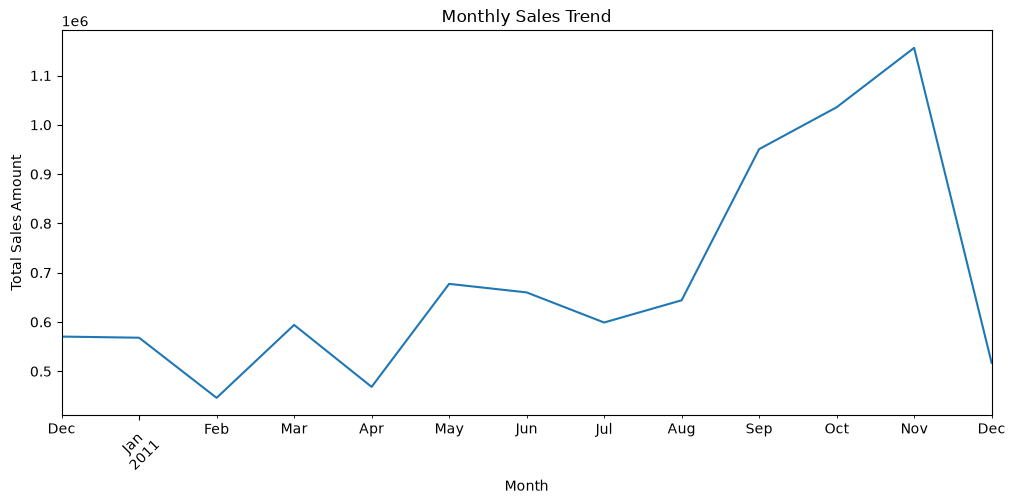

In [ ]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Create monthly sales
monthly_sales = df.groupby(
    df["InvoiceDate"].dt.to_period("M")
)["TotalAmount"].sum()

# Plot monthly sales
plt.figure(figsize=(12, 5))

monthly_sales.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.show()

### 11.5 Top 10 Products by Sales

The top products are identified based on their total sales amount to
understand which products contribute the most to overall revenue.

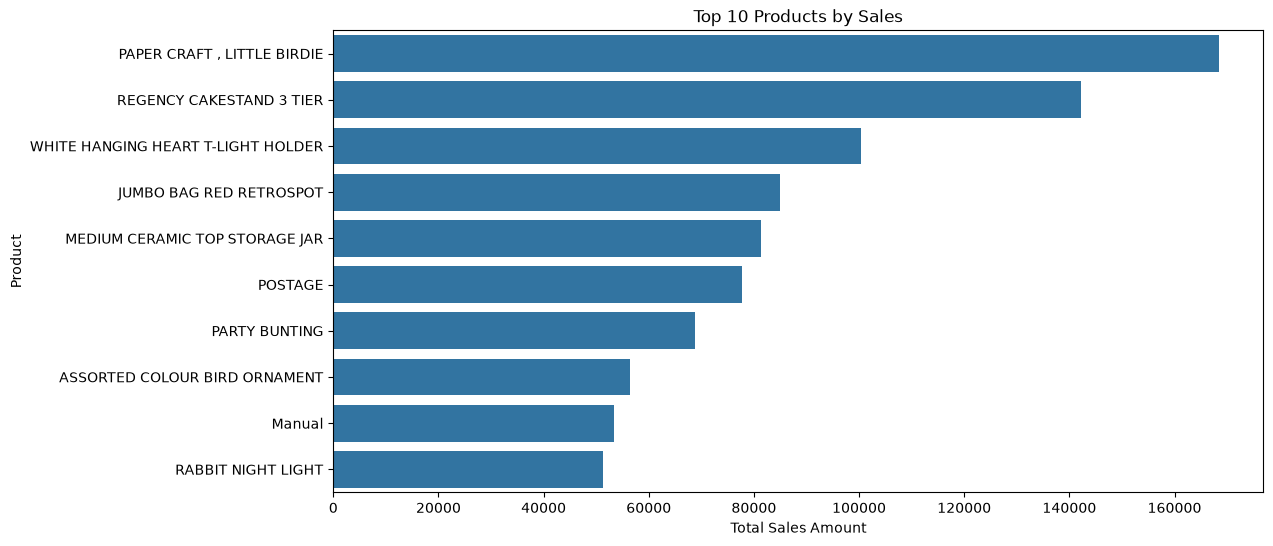

In [ ]:
top_products = (
    df.groupby("Description")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Product")

plt.show()

### 11.6 Customer Purchase Analysis

Customer-level purchase behavior is analyzed to identify customers who
generate the highest total sales.

Top 10 Customers by Total Sales:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalAmount, dtype: float64


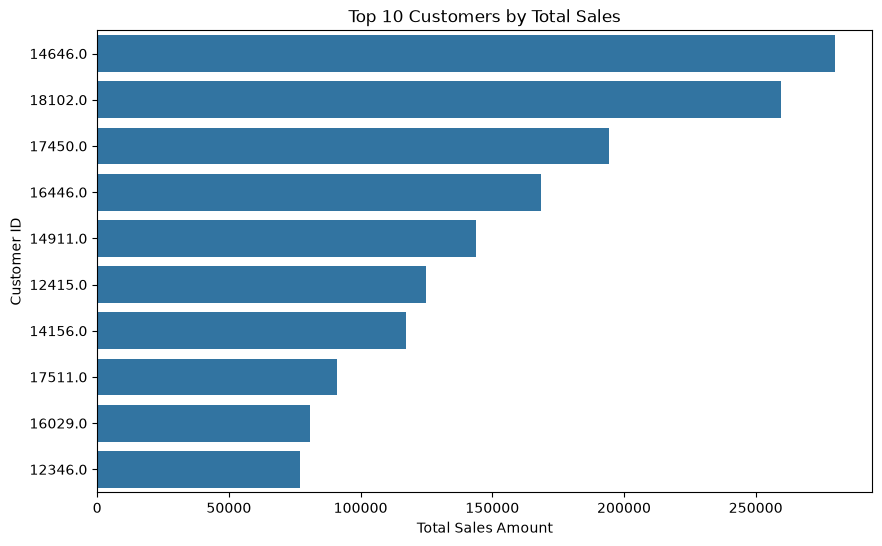

In [ ]:
# Calculate total sales for each customer
customer_sales = (
    df.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Total Sales:")
print(customer_sales)

# Plot top 10 customers
plt.figure(figsize=(10, 6))

sns.barplot(
    x=customer_sales.values,
    y=customer_sales.index.astype(str)
)

plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Customer ID")
plt.show()

### 11.7 Sales by Country

Country-level sales are analyzed to identify the countries contributing the
highest total sales revenue.

Top 10 Countries by Total Sales:
Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalAmount, dtype: float64


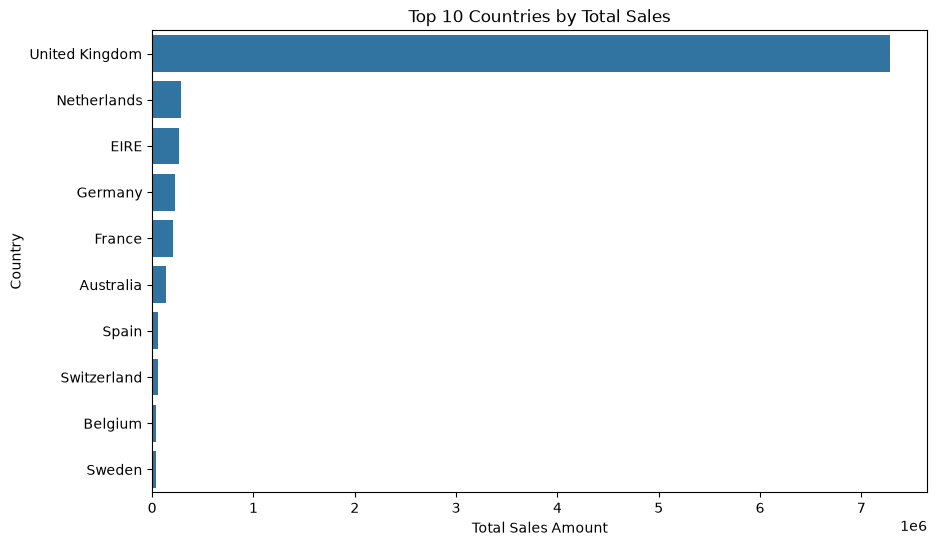

In [ ]:
# Calculate total sales by country
country_sales = (
    df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Total Sales:")
print(country_sales)

# Plot results
plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_sales.values,
    y=country_sales.index
)

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Country")
plt.show()

### 11.8 Customer Purchase Frequency

Customer purchase frequency is analyzed by counting the number of unique
invoices associated with each customer. This helps understand differences
in customer purchasing behavior and provides useful information for later
customer-level feature engineering.

In [ ]:
# Calculate number of unique invoices for each customer

customer_frequency = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Purchase Frequency:")
print(customer_frequency.head(10))

Top 10 Customers by Purchase Frequency:
CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


### 11.9 Outlier Analysis

The cleaned dataset contains highly skewed numerical variables. Boxplots are
used to identify extreme values in Quantity, UnitPrice, and TotalAmount.
Outliers are examined before deciding whether any treatment is necessary.

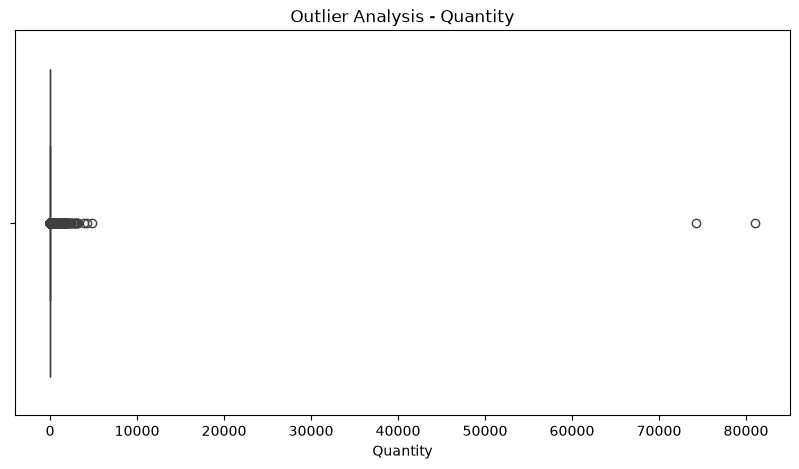

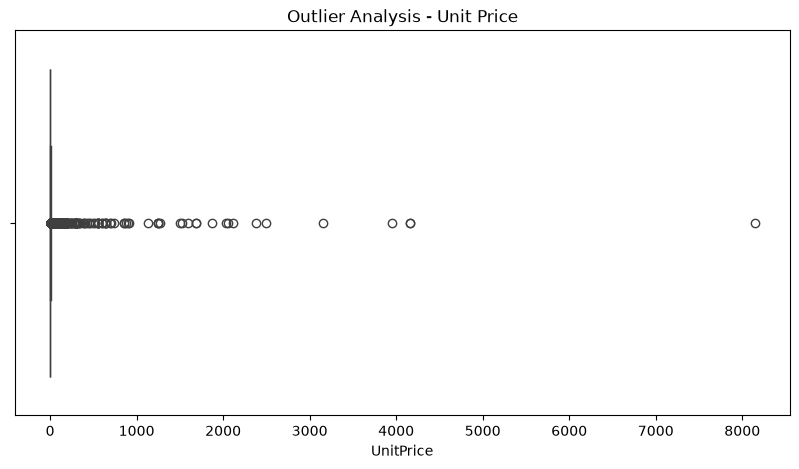

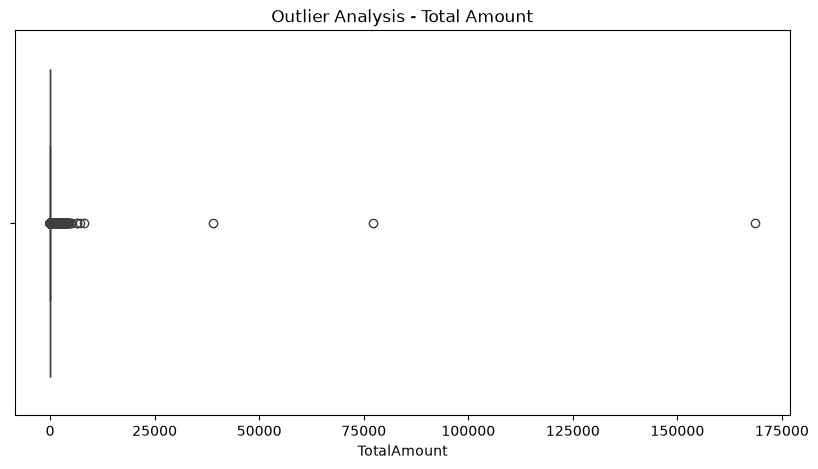

In [ ]:
# Visualize outliers using boxplots

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Quantity"])
plt.title("Outlier Analysis - Quantity")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["UnitPrice"])
plt.title("Outlier Analysis - Unit Price")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["TotalAmount"])
plt.title("Outlier Analysis - Total Amount")
plt.show()

## 12. Feature Engineering

Customer-level features are created from the transaction data to represent
historical purchasing behavior. Recency measures how recently a customer
purchased, Frequency measures purchase frequency, and Monetary represents
total spending. Additional features such as average transaction value, total
quantity purchased, and number of unique products are also created.

In [ ]:
# Set the reference date as one day after the last transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Create customer-level features
customer_features = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    AvgTransactionValue=("TotalAmount", "mean")
).reset_index()

print("Customer-level dataset shape:", customer_features.shape)

display(customer_features.head())

Customer-level dataset shape: (4338, 7)


,CustomerID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AvgTransactionValue
0,12346.0,326,1,77183.60,74215,1,77183.600000
1,12347.0,2,7,4310.00,2458,103,23.681319
2,12348.0,75,4,1797.24,2341,22,57.975484
3,12349.0,19,1,1757.55,631,73,24.076027
4,12350.0,310,1,334.40,197,17,19.670588


## 13. Target Variable Creation

The target variable represents whether a customer makes a purchase in a
future period. A time-based approach is used so that historical purchasing
behavior is used as input and future purchasing behavior is used as the
target. This prevents information from the future from leaking into the
model training data.

In [ ]:
# Define the cutoff date
cutoff_date = df["InvoiceDate"].max() - pd.Timedelta(days=30)

# Historical transactions
historical = df[df["InvoiceDate"] <= cutoff_date].copy()

# Future transactions
future = df[df["InvoiceDate"] > cutoff_date].copy()

# Create historical customer features
customer_features = historical.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (cutoff_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    AvgTransactionValue=("TotalAmount", "mean")
).reset_index()

# Customers who purchased in the future period
future_customers = set(future["CustomerID"].unique())

# Create target
customer_features["FuturePurchase"] = (
    customer_features["CustomerID"].isin(future_customers).astype(int)
)

print("Customer-level dataset:", customer_features.shape)

print("\nTarget distribution:")
print(customer_features["FuturePurchase"].value_counts())

display(customer_features.head())

Customer-level dataset: (4070, 8)

Target distribution:
FuturePurchase
0    2690
1    1380
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AvgTransactionValue,FuturePurchase
0,12346.0,295,1,77183.60,74215,1,77183.600000,0
1,12347.0,9,6,4085.18,2266,100,23.889942,1
2,12348.0,44,4,1797.24,2341,22,57.975484,0
3,12350.0,279,1,334.40,197,17,19.670588,0
4,12352.0,5,8,2506.04,536,59,29.482824,0


## 14. Feature and Target Selection

The customer purchasing behavior variables are selected as input features.
CustomerID is excluded because it is only an identifier and does not provide
meaningful predictive information.

FuturePurchase is selected as the target variable. A value of 1 indicates
that the customer made a purchase during the future period, while 0
indicates that the customer did not make a future purchase.

In [ ]:
# Select input features and target

features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts",
    "AvgTransactionValue"
]

X = customer_features[features]
y = customer_features["FuturePurchase"]

print("Selected Features:")
print(features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Selected Features:
['Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'AvgTransactionValue']

Feature shape: (4070, 6)
Target shape: (4070,)

Target distribution:
FuturePurchase
0    2690
1    1380
Name: count, dtype: int64


## 15. Train-Test Split

The customer-level dataset is divided into training and testing sets.
The training set is used to develop the machine learning models, while the
testing set is kept unseen and used to evaluate how well the models
generalize to new customer data.

Stratified sampling is used to maintain a similar proportion of both target
classes in the training and testing datasets.

In [ ]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 3256
Testing samples: 814

Training target distribution:
FuturePurchase
0    2152
1    1104
Name: count, dtype: int64

Testing target distribution:
FuturePurchase
0    538
1    276
Name: count, dtype: int64


## 16. Model Development

Four classification algorithms are developed for predicting future customer
purchases: Logistic Regression, Decision Tree, Random Forest, and Gradient
Boosting.

Logistic Regression provides a simple baseline model, while Decision Tree,
Random Forest, and Gradient Boosting can capture more complex relationships
between customer behavior features.

In [ ]:
# Define classification models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created successfully:")
for name in models:
    print("-", name)

Models created successfully:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting


## 17. Model Training and Evaluation

Each classification model is trained using the training dataset and evaluated
using the unseen testing dataset.

Accuracy, Precision, Recall, F1-score, and ROC-AUC are used to compare the
models. F1-score is particularly useful because it provides a balance
between precision and recall.

In [ ]:
# Train and evaluate all models

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1 Score",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.712531,0.605000,0.438406,0.508403,0.721503
1,Decision Tree,0.668305,0.511111,0.500000,0.505495,0.627323
3,Gradient Boosting,0.726044,0.654971,0.405797,0.501119,0.739572
0,Logistic Regression,0.722359,0.658228,0.376812,0.479263,0.732948


## 18. Hyperparameter Tuning and Cross-Validation

Hyperparameter tuning is applied to the Random Forest classifier to improve
its predictive performance. GridSearchCV is used with three-fold
cross-validation to evaluate different combinations of model parameters.

F1-score is used as the optimization metric because the target contains two
classes and F1-score provides a balance between precision and recall.

In [ ]:
# Random Forest hyperparameter tuning

rf = RandomForestClassifier(
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation F1 Score:
0.5200376928157309


## 19. Evaluation of the Tuned Random Forest

The best Random Forest model obtained through hyperparameter tuning is
evaluated on the unseen test dataset. Accuracy, Precision, Recall, F1-score,
and ROC-AUC are calculated to measure its predictive performance.

In [ ]:
# Get the best tuned Random Forest model

best_model = grid_search.best_estimator_

# Make predictions on the test data
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned, zero_division=0)
tuned_recall = recall_score(y_test, y_pred_tuned, zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_tuned, zero_division=0)
tuned_auc = roc_auc_score(y_test, y_prob_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy :", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall   :", round(tuned_recall, 4))
print("F1 Score :", round(tuned_f1, 4))
print("ROC-AUC  :", round(tuned_auc, 4))

Tuned Random Forest Results
---------------------------
Accuracy : 0.7015
Precision: 0.5829
Recall   : 0.4203
F1 Score : 0.4884
ROC-AUC  : 0.7175


## 20. Confusion Matrix

A confusion matrix is used to analyze the classification performance of the
tuned Random Forest model. It shows the numbers of correctly and incorrectly
classified customers for both classes.

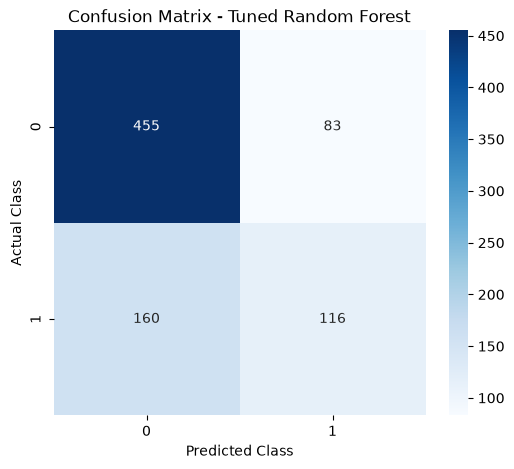

In [ ]:
# Confusion matrix for tuned Random Forest

cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## 21. Final Model Comparison

The performance of all developed models is compared with the tuned Random
Forest model using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
The comparison helps identify the model with the most suitable overall
performance for future purchase prediction.

In [ ]:
# Add tuned Random Forest results to the original model results

tuned_result = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": tuned_accuracy,
    "Precision": tuned_precision,
    "Recall": tuned_recall,
    "F1 Score": tuned_f1,
    "ROC-AUC": tuned_auc
}])

final_results = pd.concat(
    [results_df, tuned_result],
    ignore_index=True
)

final_results = final_results.sort_values(
    "F1 Score",
    ascending=False
).reset_index(drop=True)

display(final_results)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.712531,0.605000,0.438406,0.508403,0.721503
1,Decision Tree,0.668305,0.511111,0.500000,0.505495,0.627323
2,Gradient Boosting,0.726044,0.654971,0.405797,0.501119,0.739572
3,Tuned Random Forest,0.701474,0.582915,0.420290,0.488421,0.717543
4,Logistic Regression,0.722359,0.658228,0.376812,0.479263,0.732948


In [ ]:
# Select model with the highest F1-score

best_model_name = final_results.iloc[0]["Model"]

print("Best Model based on F1 Score:", best_model_name)

Best Model based on F1 Score: Random Forest


## 22. Final Model Selection

Based on the model comparison, the original Random Forest classifier is
selected as the final model.

Random Forest achieved the highest F1-score of 0.5084 among the evaluated
models. Although Gradient Boosting achieved slightly higher Accuracy and
ROC-AUC, Random Forest provided the best balance between Precision and Recall
according to the F1-score.

Therefore, Random Forest is selected as the final model for predicting future
customer purchases.

In [ ]:
# Select the original Random Forest as the final model

final_model = models["Random Forest"]

# Train final model on training data
final_model.fit(X_train, y_train)

# Final predictions
final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)[:, 1]

print("Final Model: Random Forest")
print("Accuracy :", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, final_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, final_prob), 4))

Final Model: Random Forest
Accuracy : 0.7125
Precision: 0.605
Recall   : 0.4384
F1 Score : 0.5084
ROC-AUC  : 0.7215


## 23. Feature Importance

Feature importance is analyzed using the final Random Forest model to
understand which customer behavior variables contribute most to the
prediction of future purchases.

Feature Importance:
Monetary               0.196368
TotalQuantity          0.191959
Recency                0.166761
AvgTransactionValue    0.163804
UniqueProducts         0.152706
Frequency              0.128402
dtype: float64


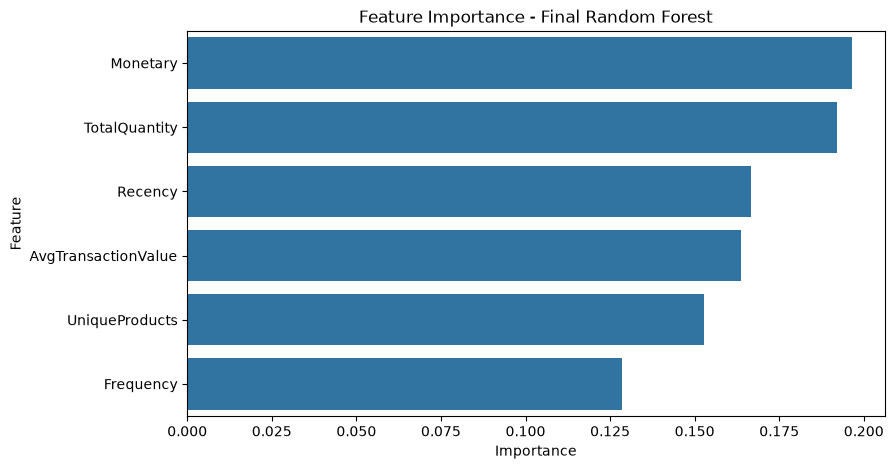

In [ ]:
# Calculate feature importance

feature_importance = pd.Series(
    final_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

# Plot feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title("Feature Importance - Final Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 24. Sample / Unseen Data Prediction

A new customer record is provided to the final Random Forest model to
demonstrate how the developed system can predict future purchase behavior
for previously unseen customer data.

The input contains customer purchasing behavior such as Recency, Frequency,
Monetary value, Total Quantity, Unique Products, and Average Transaction
Value.

In [ ]:
# Create a new unseen customer

new_customer = pd.DataFrame({
    "Recency": [15],
    "Frequency": [8],
    "Monetary": [500.0],
    "TotalQuantity": [250],
    "UniqueProducts": [30],
    "AvgTransactionValue": [62.5]
})

# Predict future purchase

prediction = final_model.predict(new_customer)[0]

# Calculate probability

probability = final_model.predict_proba(new_customer)[0][1]

print("New Customer Data:")
display(new_customer)

print("\nPredicted Class:", prediction)
print("Purchase Probability:", round(probability, 4))

if prediction == 1:
    print("Result: Customer is likely to make a future purchase.")
else:
    print("Result: Customer is unlikely to make a future purchase.")

New Customer Data:


,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AvgTransactionValue
0,15,8,500.0,250,30,62.5



Predicted Class: 0
Purchase Probability: 0.26
Result: Customer is unlikely to make a future purchase.


## 25. Saving the Final Model

The selected Random Forest model is saved as a reusable model file using
Joblib. Saving the trained model allows it to be loaded later and used for
predictions on new customer data without retraining the model.

In [ ]:
import joblib

joblib.dump(
    final_model,
    "models/final_customer_purchase_model.pkl"
)

print("Final Random Forest model saved successfully.")

Final Random Forest model saved successfully.


## 26. Saving the Customer-Level Dataset

The engineered customer-level dataset is saved as a CSV file in the outputs
folder. This dataset contains the customer behavior features and the target
variable used in the machine learning project.

In [ ]:
customer_features.to_csv(
    "outputs/customer_features.csv",
    index=False
)

print("Customer feature dataset saved successfully.")

Customer feature dataset saved successfully.


## 27. Final Project Verification

The final project results are summarized to verify that the complete
machine learning workflow has been successfully executed. The summary
includes the cleaned transaction count, number of customers, final model
performance, and prediction on unseen customer data.

In [ ]:
print("========== PROJECT SUMMARY ==========")

print("Original transactions: 541909")
print("Final cleaned transactions:", len(df))
print("Customers used for ML:", len(customer_features))

print("\nFinal Model: Random Forest")

print("Accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, final_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, final_prob), 4))

print("\nUnseen Customer Prediction:", prediction)
print("Purchase Probability:", round(probability, 4))

print("\nProject completed successfully!")

========== PROJECT SUMMARY ==========
Original transactions: 541909
Final cleaned transactions: 392692
Customers used for ML: 4070

Final Model: Random Forest
Accuracy: 0.7125
Precision: 0.605
Recall: 0.4384
F1 Score: 0.5084
ROC-AUC: 0.7215

Unseen Customer Prediction: 0
Purchase Probability: 0.26

Project completed successfully!
